## III. Notebook 3: Regressão Linear

Este *notebook* utiliza o modelo de **Regressão Linear** para prever a **Taxa de Alfabetização** dos **municípios** com base em 8 indicadores demográficos.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [2]:
df_municipios = pd.read_excel('../data/censo2022/br_ibge_censo_2022_municipio.xlsx')
df_alfabetizacao = pd.read_excel('../data/censo2022/br_ibge_censo_2022_alfabetizacao_grupo_idade_sexo_raca.xlsx')

In [3]:

df_alfabetizacao_agg = df_alfabetizacao.groupby('id_municipio').apply(
    lambda x: (x[x['alfabetizacao'] == 'Sim']['populacao'].sum() / x['populacao'].sum()) * 100
).reset_index()
df_alfabetizacao_agg.columns = ['id_municipio', 'taxa_alfabetizacao_calculada']

df_completo = pd.merge(df_municipios, df_alfabetizacao_agg, on='id_municipio', how='left')

y = df_completo['taxa_alfabetizacao']
target_name = 'Taxa de Alfabetização (%)'

variaveis_predictoras = [
    'idade_mediana', 'indice_envelhecimento', 'razao_sexo',
    'populacao_indigena', 'populacao_quilombola', 'populacao', 'domicilios', 'area'
]

variaveis_disponiveis = [var for var in variaveis_predictoras if var in df_completo.columns]
print(f"Variáveis preditoras disponíveis: {variaveis_disponiveis}")

X = df_completo[variaveis_disponiveis]

Variáveis preditoras disponíveis: ['idade_mediana', 'indice_envelhecimento', 'razao_sexo', 'populacao_indigena', 'populacao_quilombola', 'populacao', 'domicilios', 'area']


In [4]:
# Preencher valores ausentes com a mediana
for coluna in variaveis_disponiveis:
    if X[coluna].isna().sum() > 0:
        mediana = X[coluna].median()
        X[coluna] = X[coluna].fillna(mediana)
        print(f"Coluna {coluna}: {X[coluna].isna().sum()} NaN preenchidos com mediana {mediana:.2f}")

# Remover outliers usando Z-score (apenas para variáveis numéricas contínuas)
z_scores = np.abs(stats.zscore(X.select_dtypes(include=[np.number])))
outliers = (z_scores > 3).any(axis=1)
print(f"Identificados {outliers.sum()} outliers (Z-score > 3)")

# Remover outliers do conjunto completo
mask_sem_outliers = ~outliers
X_clean = X[mask_sem_outliers]
y_clean = y[mask_sem_outliers]

Identificados 335 outliers (Z-score > 3)


In [5]:
# DIVISÃO TREINO/TESTE

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_clean, y_clean, test_size=0.3, random_state=42, shuffle=True
)

print(f"Conjunto de treino: {X_treino.shape}")
print(f"Conjunto de teste: {X_teste.shape}")

scaler = StandardScaler()
X_treino_scaled = scaler.fit_transform(X_treino)
X_teste_scaled = scaler.transform(X_teste)

print("Variáveis preditoras padronizadas (StandardScaler)")

Conjunto de treino: (3664, 8)
Conjunto de teste: (1571, 8)
Variáveis preditoras padronizadas (StandardScaler)


In [6]:
# TREINAMENTO DO MODELO

modelo = LinearRegression()
modelo.fit(X_treino_scaled, y_treino)

# DataFrame com coeficientes
coeficientes = pd.DataFrame({
    'Variável': variaveis_disponiveis,
    'Coeficiente': modelo.coef_,
    'Coeficiente_Absoluto': np.abs(modelo.coef_)
})

coeficientes = coeficientes.sort_values('Coeficiente_Absoluto', ascending=False)

print("\nCoeficientes da regressão (ordenados por importância):")
for _, row in coeficientes.iterrows():
    sinal = "+" if row['Coeficiente'] > 0 else "-"
    print(f"  {row['Variável']:25} {sinal} {abs(row['Coeficiente']):.4f}")

print(f"\nIntercepto (constante): {modelo.intercept_:.4f}")



Coeficientes da regressão (ordenados por importância):
  idade_mediana             + 0.0708
  indice_envelhecimento     - 0.0377
  populacao                 + 0.0121
  area                      + 0.0101
  populacao_quilombola      - 0.0075
  domicilios                + 0.0073
  razao_sexo                + 0.0024
  populacao_indigena        + 0.0023

Intercepto (constante): 0.8820


In [7]:
# AVALIAÇÃO E MÉTRICAS DE ERRO

y_pred_treino = modelo.predict(X_treino_scaled)
y_pred_teste = modelo.predict(X_teste_scaled)

r2_treino = r2_score(y_treino, y_pred_treino)
r2_teste = r2_score(y_teste, y_pred_teste)

mse_treino = mean_squared_error(y_treino, y_pred_treino)
mse_teste = mean_squared_error(y_teste, y_pred_teste)

mae_treino = mean_absolute_error(y_treino, y_pred_treino)
mae_teste = mean_absolute_error(y_teste, y_pred_teste)

rmse_treino = np.sqrt(mse_treino)
rmse_teste = np.sqrt(mse_teste)

print("\nMÉTRICAS DE DESEMPENHO:")
print(f"{'Métrica':<15} {'Treino':<10} {'Teste':<10}")
print(f"{'-' * 40}")
print(f"{'R²':<15} {r2_treino:<10.4f} {r2_teste:<10.4f}")
print(f"{'MSE':<15} {mse_treino:<10.2f} {mse_teste:<10.2f}")
print(f"{'RMSE':<15} {rmse_treino:<10.2f} {rmse_teste:<10.2f}")
print(f"{'MAE':<15} {mae_treino:<10.2f} {mae_teste:<10.2f}")


print("\nAnálise de resíduos...")

residuos_teste = y_teste - y_pred_teste

print(f"Média dos resíduos: {residuos_teste.mean():.4f}")
print(f"Desvio padrão dos resíduos: {residuos_teste.std():.4f}")

stat, p_value = stats.shapiro(residuos_teste)
print(f"Teste de normalidade (Shapiro-Wilk): p-value = {p_value:.4f}")
if p_value > 0.05:
    print("Resíduos seguem distribuição normal")
else:
    print("Resíduos não seguem distribuição normal")



MÉTRICAS DE DESEMPENHO:
Métrica         Treino     Teste     
----------------------------------------
R²              0.2937     0.3136    
MSE             0.00       0.00      
RMSE            0.06       0.06      
MAE             0.05       0.05      

Análise de resíduos...
Média dos resíduos: -0.0014
Desvio padrão dos resíduos: 0.0642
Teste de normalidade (Shapiro-Wilk): p-value = 0.0000
Resíduos não seguem distribuição normal


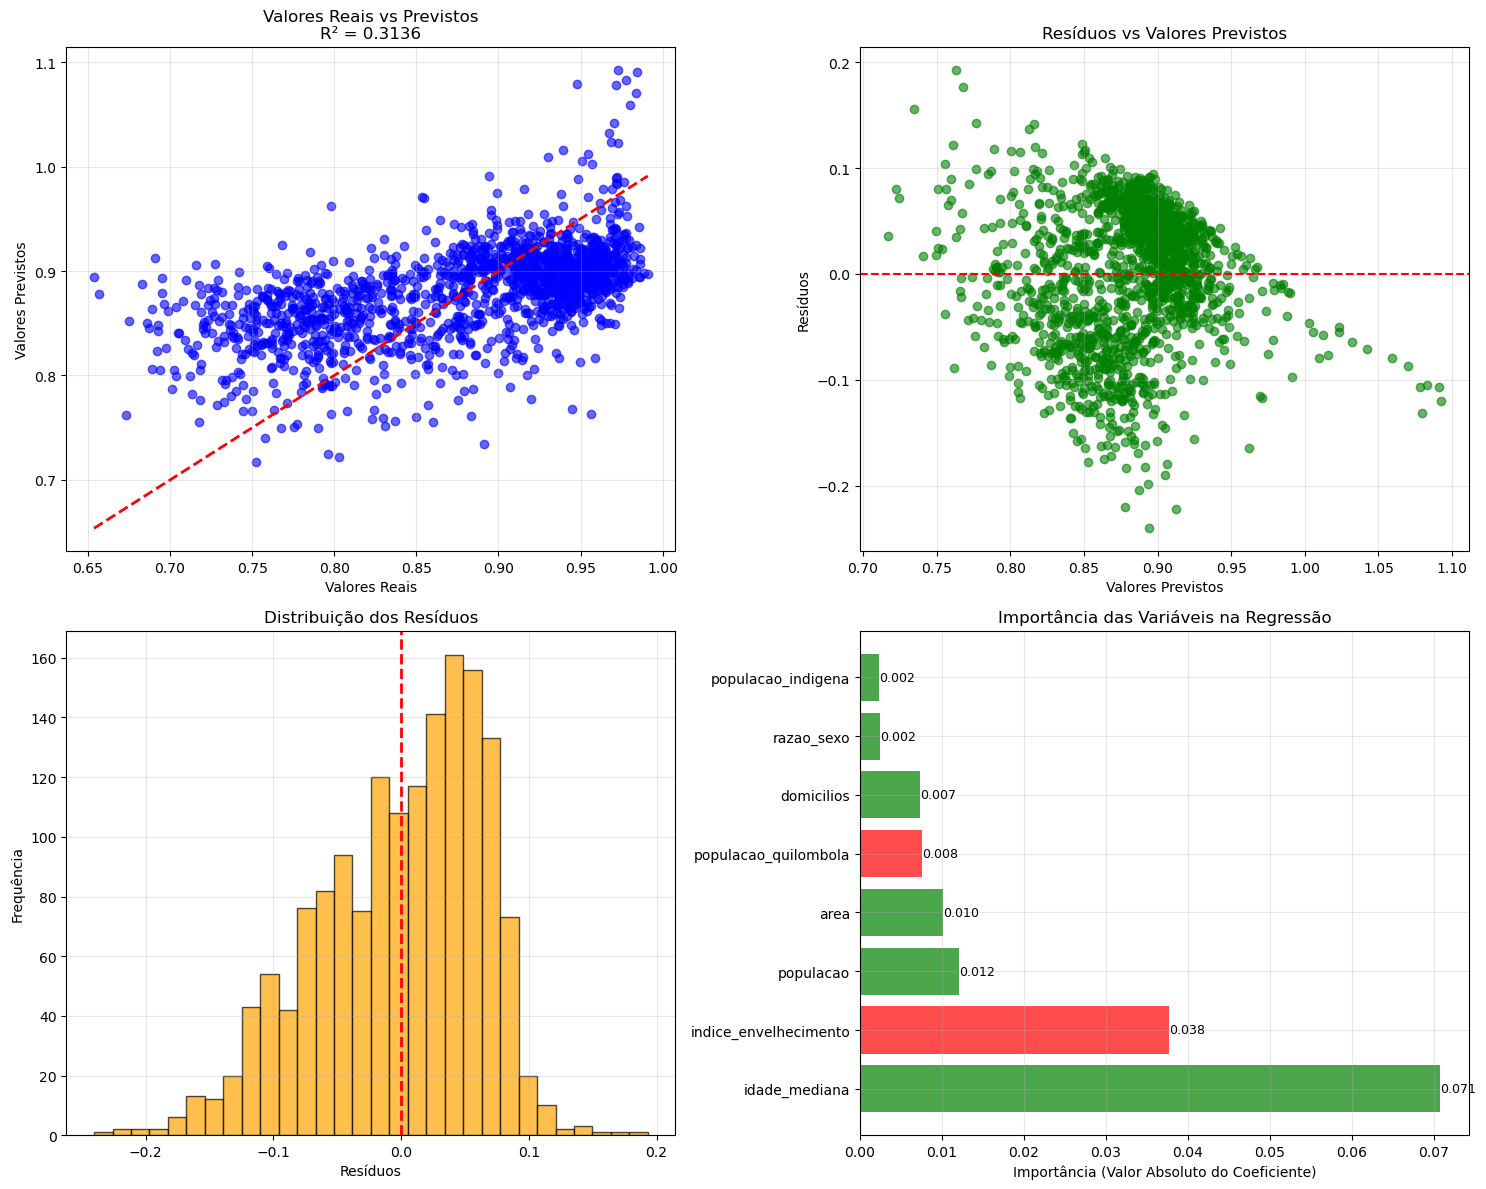

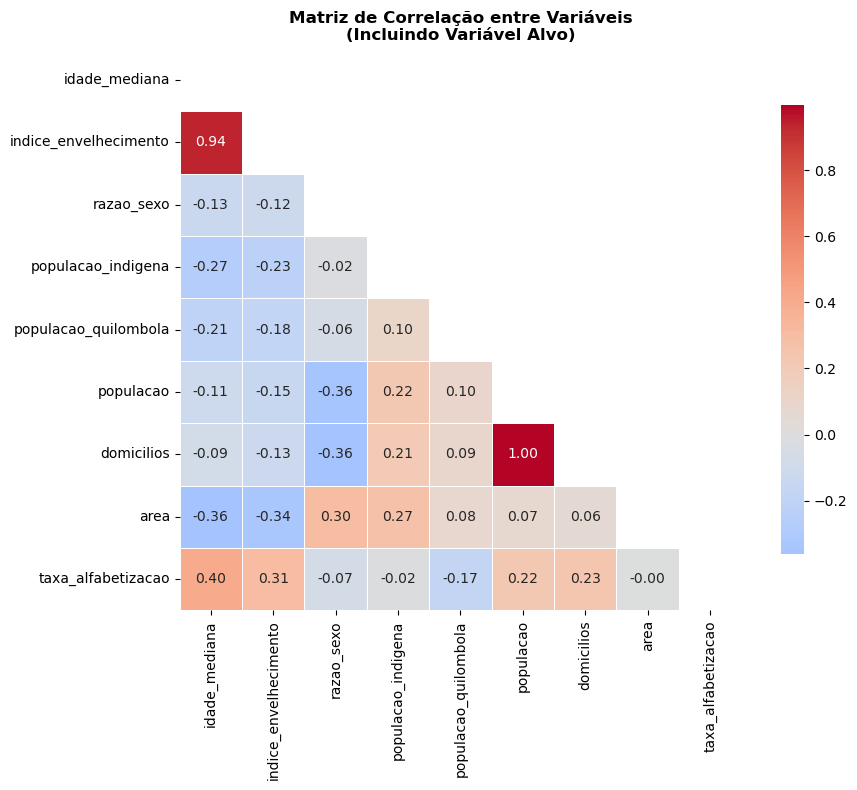

In [8]:
# VISUALIZAÇÕES

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

axes[0,0].scatter(y_teste, y_pred_teste, alpha=0.6, color='blue')
axes[0,0].plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)
axes[0,0].set_xlabel('Valores Reais')
axes[0,0].set_ylabel('Valores Previstos')
axes[0,0].set_title(f'Valores Reais vs Previstos\nR² = {r2_teste:.4f}')
axes[0,0].grid(True, alpha=0.3)

axes[0,1].scatter(y_pred_teste, residuos_teste, alpha=0.6, color='green')
axes[0,1].axhline(y=0, color='r', linestyle='--')
axes[0,1].set_xlabel('Valores Previstos')
axes[0,1].set_ylabel('Resíduos')
axes[0,1].set_title('Resíduos vs Valores Previstos')
axes[0,1].grid(True, alpha=0.3)

axes[1,0].hist(residuos_teste, bins=30, alpha=0.7, color='orange', edgecolor='black')
axes[1,0].axvline(x=0, color='r', linestyle='--', linewidth=2)
axes[1,0].set_xlabel('Resíduos')
axes[1,0].set_ylabel('Frequência')
axes[1,0].set_title('Distribuição dos Resíduos')
axes[1,0].grid(True, alpha=0.3)

colors = ['green' if x > 0 else 'red' for x in coeficientes['Coeficiente']]
bars = axes[1,1].barh(
    coeficientes['Variável'], 
    coeficientes['Coeficiente_Absoluto'], 
    color=colors, 
    alpha=0.7
)

axes[1,1].set_xlabel('Importância (Valor Absoluto do Coeficiente)')
axes[1,1].set_title('Importância das Variáveis na Regressão')
axes[1,1].grid(True, alpha=0.3)

for bar in bars:
    width = bar.get_width()
    axes[1,1].text(
        width, 
        bar.get_y() + bar.get_height()/2, 
        f'{width:.3f}',
        ha='left', 
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.savefig('../resultados/regressao_resultados.png', dpi=300, bbox_inches='tight')
plt.show()

# MATRIZ DE CORRELAÇÃO
plt.figure(figsize=(10, 8))
correlation_matrix = pd.concat([X_clean, y_clean], axis=1).corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix, 
    mask=mask, 
    annot=True, 
    cmap='coolwarm', 
    center=0,
    fmt='.2f', 
    square=True, 
    linewidths=0.5, 
    cbar_kws={"shrink": .8}
)

plt.title('Matriz de Correlação entre Variáveis\n(Incluindo Variável Alvo)', fontweight='bold')
plt.tight_layout()
plt.savefig('../resultados/matriz_correlacao_regressao.png', dpi=300, bbox_inches='tight')
plt.show()


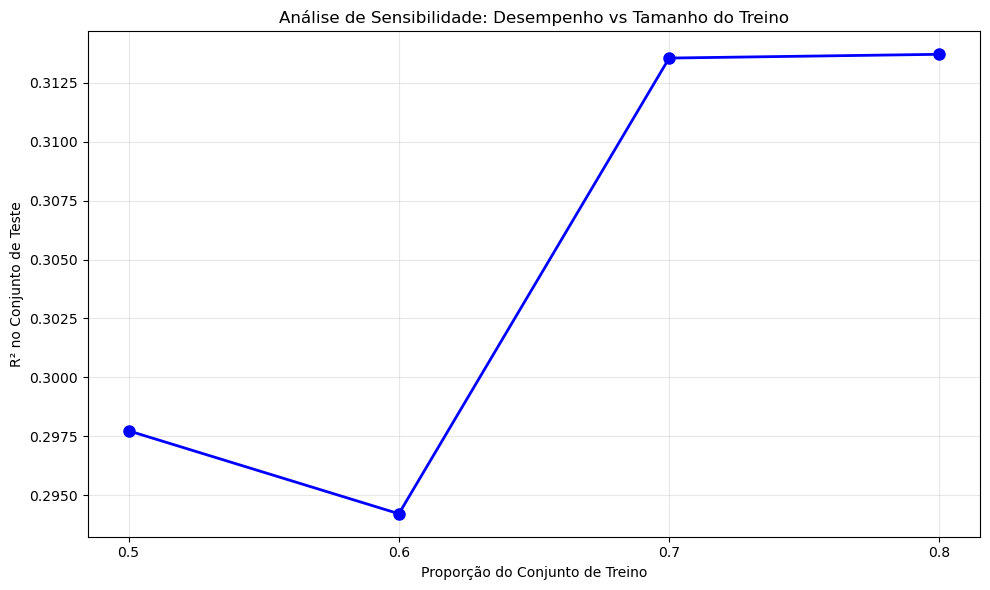


Resultados da análise de sensibilidade:
   Tamanho_Treino  Amostras_Treino  R2_Teste
0             0.5             2617    0.2977
1             0.6             3141    0.2942
2             0.7             3664    0.3136
3             0.8             4188    0.3137


In [9]:
tamanhos_treino = [0.5, 0.6, 0.7, 0.8]
resultados_sensibilidade = []

for tamanho in tamanhos_treino:
    X_train_temp, X_test_temp, y_train_temp, y_test_temp = train_test_split(
        X_clean, y_clean, test_size=1-tamanho, random_state=42
    )
    
    # Padronizar
    scaler_temp = StandardScaler()
    X_train_temp_scaled = scaler_temp.fit_transform(X_train_temp)
    X_test_temp_scaled = scaler_temp.transform(X_test_temp)
    
    # Treinar modelo
    modelo_temp = LinearRegression()
    modelo_temp.fit(X_train_temp_scaled, y_train_temp)
    
    # Avaliar
    y_pred_temp = modelo_temp.predict(X_test_temp_scaled)
    r2_temp = r2_score(y_test_temp, y_pred_temp)
    
    resultados_sensibilidade.append({
        'Tamanho_Treino': tamanho,
        'Amostras_Treino': len(X_train_temp),
        'R2_Teste': r2_temp
    })

df_sensibilidade = pd.DataFrame(resultados_sensibilidade)

plt.figure(figsize=(10, 6))
plt.plot(df_sensibilidade['Tamanho_Treino'], df_sensibilidade['R2_Teste'], 'bo-', linewidth=2, markersize=8)
plt.xlabel('Proporção do Conjunto de Treino')
plt.ylabel('R² no Conjunto de Teste')
plt.title('Análise de Sensibilidade: Desempenho vs Tamanho do Treino')
plt.grid(True, alpha=0.3)
plt.xticks(tamanhos_treino)
plt.tight_layout()
plt.savefig('../resultados/sensibilidade_tamanho_treino.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nResultados da análise de sensibilidade:")
print(df_sensibilidade.round(4))


In [10]:
print("\n EXEMPLOS DE PREVISÃO")

indices_amostra = np.random.choice(len(X_teste), min(5, len(X_teste)), replace=False)

print(f"\nExemplos de previsão (amostra do conjunto de teste):")
print(f"{'Amostra':<8} {'Real':<12} {'Previsto':<12} {'Erro':<10} {'Erro (%)':<10}")
print("-" * 60)

for i, idx in enumerate(indices_amostra):
    real = y_teste.iloc[idx]
    previsto = y_pred_teste[idx]
    erro_abs = abs(real - previsto)
    erro_percentual = (erro_abs / real) * 100 if real != 0 else 0
    
    print(f"{i+1:<8} {real:<12.2f} {previsto:<12.2f} {erro_abs:<10.2f} {erro_percentual:<10.1f}%")


 EXEMPLOS DE PREVISÃO

Exemplos de previsão (amostra do conjunto de teste):
Amostra  Real         Previsto     Erro       Erro (%)  
------------------------------------------------------------
1        0.86         0.87         0.02       1.8       %
2        0.93         0.84         0.09       9.6       %
3        0.93         0.87         0.06       6.8       %
4        0.92         0.91         0.00       0.4       %
5        0.97         0.92         0.05       4.8       %


In [11]:
# INTERPRETAÇÃO FINAL DO MODELO

print(f"\nVARIÁVEL ALVO: {target_name}")
print(f"R² FINAL: {r2_teste:.4f}")

if r2_teste > 0.7:
    interpretacao_r2 = "Excelente - modelo explica bem a variabilidade dos dados"
elif r2_teste > 0.5:
    interpretacao_r2 = "Bom - modelo tem poder explicativo moderado"
elif r2_teste > 0.3:
    interpretacao_r2 = "Regular - modelo tem algum poder explicativo"
else:
    interpretacao_r2 = "Baixo - modelo tem limitado poder explicativo"

print(f"INTERPRETAÇÃO DO R²: {interpretacao_r2}")

print(f"\nVARIÁVEIS MAIS IMPORTANTES:")
top_3 = coeficientes.head(3)
for _, row in top_3.iterrows():
    impacto = "POSITIVO" if row['Coeficiente'] > 0 else "NEGATIVO"
    print(f"  • {row['Variável']}: {impacto} (coeficiente: {row['Coeficiente']:.4f})")

print(f"\nEQUAÇÃO DA REGRESSÃO:")
equacao = f"Y = {modelo.intercept_:.2f}"
for coef, var in zip(modelo.coef_, variaveis_disponiveis):
    sinal = " + " if coef > 0 else " - "
    equacao += f"{sinal}{abs(coef):.2f}×{var}"
print(equacao)


VARIÁVEL ALVO: Taxa de Alfabetização (%)
R² FINAL: 0.3136
INTERPRETAÇÃO DO R²: Regular - modelo tem algum poder explicativo

VARIÁVEIS MAIS IMPORTANTES:
  • idade_mediana: POSITIVO (coeficiente: 0.0708)
  • indice_envelhecimento: NEGATIVO (coeficiente: -0.0377)
  • populacao: POSITIVO (coeficiente: 0.0121)

EQUAÇÃO DA REGRESSÃO:
Y = 0.88 + 0.07×idade_mediana - 0.04×indice_envelhecimento + 0.00×razao_sexo + 0.00×populacao_indigena - 0.01×populacao_quilombola + 0.01×populacao + 0.01×domicilios + 0.01×area
